# Imports Libraries & Tools

In [1]:
import os  # For directory and file operations
import sys  # For adding the project root to the Python import path
import numpy as np  # For numerical operations and handling image arrays
import random  # For generating random values for augmentation
from PIL import Image, ImageEnhance  # For image processing and enhancement
from tensorflow.keras.preprocessing.image import load_img  # For loading images
from tensorflow.keras.models import Sequential  # For building the model
from tensorflow.keras.layers import Input, Flatten, Dropout, Dense  # For model layers
from tensorflow.keras.optimizers import Adam  # For optimizer
from tensorflow.keras.applications import VGG16  # For using VGG16 model
from sklearn.utils import shuffle  # For shuffling the data
from sklearn.model_selection import train_test_split  # For a strict stratified split

# Add the project root to sys.path so the local 'src' package can be imported
sys.path.append(os.path.abspath(".."))

from src.config import (  # Project configuration paths
    RAW_DATA_DIR,
    VALID_EXTENSIONS,
    MODELS_DIR,
    TEST_SIZE,
    RANDOM_STATE,
)
# Global image size for preprocessing
IMAGE_SIZE = 128


I0000 00:00:1792322178.342966   30236 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322178.343544   30236 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792322178.402030   30236 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792322180.080301   30236 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792322180.080712   30236 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### Extension validation

In [2]:
def is_valid_extension(file_path):
    """
    Vérifie si le fichier possède une extension d'image valide
    (insensible à la casse : .JPG, .png, etc.).
    """
    return file_path.lower().endswith(VALID_EXTENSIONS)


# Classes = sous-dossiers de RAW_DATA_DIR, triés pour un encodage stable et reproductible
CLASS_NAMES = sorted(
    name for name in os.listdir(RAW_DATA_DIR)
    if os.path.isdir(os.path.join(RAW_DATA_DIR, name))
)
NUM_CLASSES = len(CLASS_NAMES)

valid_paths = []
invalid_count = 0

for root, dirs, files in os.walk(RAW_DATA_DIR):
    for file_name in files:
        file_path = os.path.join(root, file_name)

        # 1. Validation de l'extension
        if not is_valid_extension(file_path):
            invalid_count += 1
            continue  # Ignore et passe au fichier suivant

        valid_paths.append(file_path)

print(f"Classes détectées ({NUM_CLASSES}) : {CLASS_NAMES}")
print(f"Fichiers valides retenus : {len(valid_paths)}")
print(f"Fichiers ignorés (mauvaise extension) : {invalid_count}")


Classes détectées (4) : ['glioma', 'meningioma', 'notumor', 'pituitary']
Fichiers valides retenus : 7023
Fichiers ignorés (mauvaise extension) : 0


### Loading Dataset

In [3]:
# Collect every labelled image (only the class sub-folders of RAW_DATA_DIR)
all_paths, all_labels = [], []
for label in CLASS_NAMES:
    label_dir = os.path.join(RAW_DATA_DIR, label)
    for image in sorted(os.listdir(label_dir)):
        file_path = os.path.join(label_dir, image)
        if not os.path.isfile(file_path) or not is_valid_extension(file_path):
            continue
        all_paths.append(file_path)
        all_labels.append(label)

# Strict stratified train/test split -> metrics are computed on unseen images only
train_paths, test_paths, train_labels, test_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=TEST_SIZE,
    stratify=all_labels,
    random_state=RANDOM_STATE,
)


def label_counts(labels):
    return {label: labels.count(label) for label in CLASS_NAMES}


print(f"Total : {len(all_paths)} images  {label_counts(all_labels)}")
print(f"Train : {len(train_paths)} images  {label_counts(train_labels)}")
print(f"Test  : {len(test_paths)} images  {label_counts(test_labels)}")


Total : 7023 images  {'glioma': 1621, 'meningioma': 1645, 'notumor': 2000, 'pituitary': 1757}
Train : 5618 images  {'glioma': 1297, 'meningioma': 1316, 'notumor': 1600, 'pituitary': 1405}
Test  : 1405 images  {'glioma': 324, 'meningioma': 329, 'notumor': 400, 'pituitary': 352}


### Data visualization

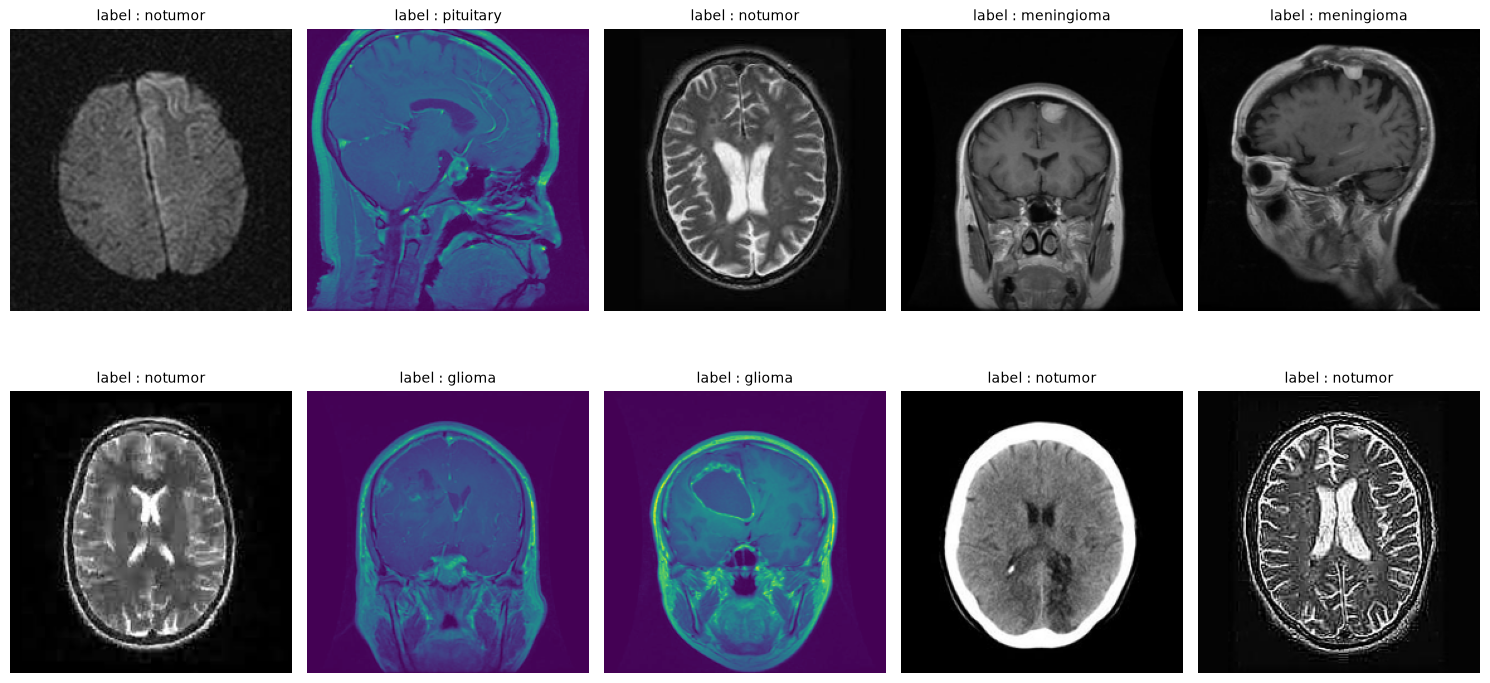

In [4]:
import random
from PIL import Image
import matplotlib.pyplot as plt
import os

# select 10 random indices to visualize 10 images
random.seed(RANDOM_STATE)

random_indices = random.sample(range(len(train_paths)), 10)
fig, axes = plt.subplots(2, 5, figsize=(15, 8))
axes = axes.ravel()
for i, idx in enumerate(random_indices):
    img_path = train_paths[idx]
    img = Image.open(img_path)
    img = img.resize((224, 224))

    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(f"label : {train_labels[idx]}", fontsize=10)

plt.tight_layout()
plt.show()


### Image preprocessing (Helper functions)

In [5]:
# Image augmentation function
def augment_image(image):
    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.uint8(image))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))
    image = np.array(image)
    return image


# Load images; augmentation is applied on the training set only (exact evaluation)
def open_images(paths, augment=True):
    images = []
    for path in paths:
        img = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        if augment:
            img = augment_image(img)
        img_arr = img_to_array(img)
        img_arr = preprocess_input(img_arr)
        images.append(img_arr)
    return np.array(images)


# Encoding labels (convert label names to integers)
def encode_label(labels):
    encoded = [CLASS_NAMES.index(label) for label in labels]
    return np.array(encoded)


# Data generator for batching
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i + batch_size]
            batch_images = open_images(batch_paths)  # Open and augment images
            batch_labels = labels[i:i + batch_size]
            batch_labels = encode_label(batch_labels)  # Encode labels
            yield batch_images, batch_labels  # Yield the batch


### Model

In [6]:
IMAGE_SIZE = 128
base_model = VGG16(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), include_top=False, weights='imagenet')

for layer in base_model.layers:
    layer.trainable = False

base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

model = Sequential()
model.add(Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)))
model.add(base_model)
model.add(Flatten())
model.add(Dropout(0.3))

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(NUM_CLASSES, activation='softmax'))

model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_accuracy'])

batch_size = 20

steps = int(len(train_paths)/ batch_size)

epochs = 5


history = model.fit(
    datagen(train_paths, train_labels, batch_size=batch_size, epochs=epochs),
    steps_per_epoch=steps,
    epochs=epochs
)


E0000 00:00:1792322183.261703   30236 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/5


/home/moali/projects/brainscan/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792322183.938880   30236 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


  1/280 ━━━━━━━━━━━━━━━━━━━━ 12:22 3s/step - loss: 10.4667 - sparse_categorical_accuracy: 0.4500

  2/280 ━━━━━━━━━━━━━━━━━━━━ 2:53 624ms/step - loss: 9.3607 - sparse_categorical_accuracy: 0.3750

...

277/280 ━━━━━━━━━━━━━━━━━━━━ 2s 883ms/step - loss: 0.1827 - sparse_categorical_accuracy: 0.9354

278/280 ━━━━━━━━━━━━━━━━━━━━ 1s 883ms/step - loss: 0.1825 - sparse_categorical_accuracy: 0.9354

279/280 ━━━━━━━━━━━━━━━━━━━━ 0s 883ms/step - loss: 0.1819 - sparse_categorical_accuracy: 0.9356

280/280 ━━━━━━━━━━━━━━━━━━━━ 0s 883ms/step - loss: 0.1814 - sparse_categorical_accuracy: 0.9359

280/280 ━━━━━━━━━━━━━━━━━━━━ 247s 883ms/step - loss: 0.1814 - sparse_categorical_accuracy: 0.9359


### Model evaluation

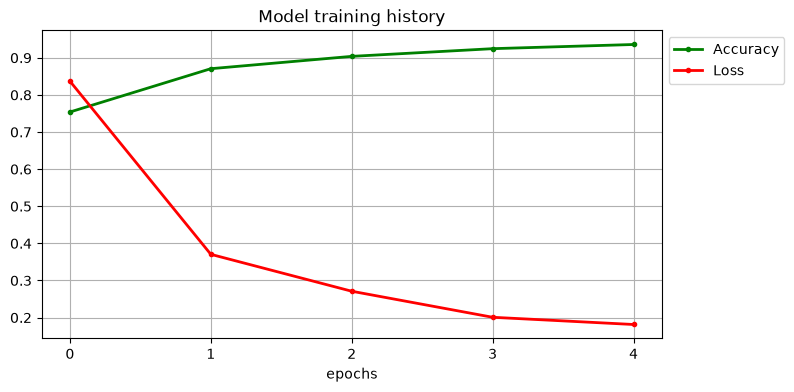

In [7]:
# type(history)

plt.figure(figsize=(8,4))
plt.grid(True)
plt.plot(history.history['sparse_categorical_accuracy'], '.g-', linewidth=2)
plt.plot(history.history['loss'], '.r-', linewidth=2)
plt.title('Model training history')
plt.xlabel('epochs')
plt.xticks([x for x in range(epochs)])
plt.legend(['Accuracy', 'Loss'], loc='upper left', bbox_to_anchor=(1, 1))
plt.show()


### Model classification reports

In [8]:
from sklearn.metrics import classification_report, roc_curve, confusion_matrix, auc
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import label_binarize
import numpy as np

test_images = open_images(test_paths, augment=False)  # no augmentation on the test set
test_labels_encoded = encode_label(test_labels)

test_predictions = model.predict(test_images)

print("Classification report is : ")
print(classification_report(test_labels_encoded, np.argmax(test_predictions, axis=1),
                            target_names=CLASS_NAMES, digits=3))


 1/44 ━━━━━━━━━━━━━━━━━━━━ 1:51 3s/step

 2/44 ━━━━━━━━━━━━━━━━━━━━ 1:53 3s/step

 3/44 ━━━━━━━━━━━━━━━━━━━━ 1:43 3s/step

 4/44 ━━━━━━━━━━━━━━━━━━━━ 1:31 2s/step

 5/44 ━━━━━━━━━━━━━━━━━━━━ 1:16 2s/step

...

42/44 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step

43/44 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step

44/44 ━━━━━━━━━━━━━━━━━━━━ 52s 1s/step


Classification report is : 
              precision    recall  f1-score   support

      glioma      0.931     0.957     0.944       324
  meningioma      0.930     0.842     0.884       329
     notumor      0.987     0.983     0.985       400
   pituitary      0.918     0.980     0.948       352

    accuracy                          0.943      1405
   macro avg      0.941     0.940     0.940      1405
weighted avg      0.943     0.943     0.942      1405



### Model confusion plot

Confusion Matrix
[[310  13   0   1]
 [ 20 277   5  27]
 [  1   3 393   3]
 [  2   5   0 345]]


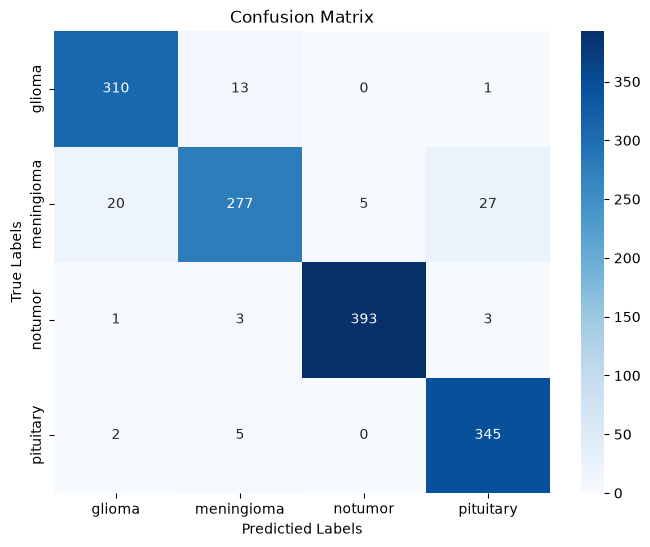

In [9]:
conf_matrix = confusion_matrix(test_labels_encoded, np.argmax(test_predictions, axis=1))
print("Confusion Matrix")
print(conf_matrix)

# Plot the confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)

plt.title("Confusion Matrix")
plt.xlabel("Predictied Labels")
plt.ylabel("True Labels")
plt.show()


### Roc Curve Plot

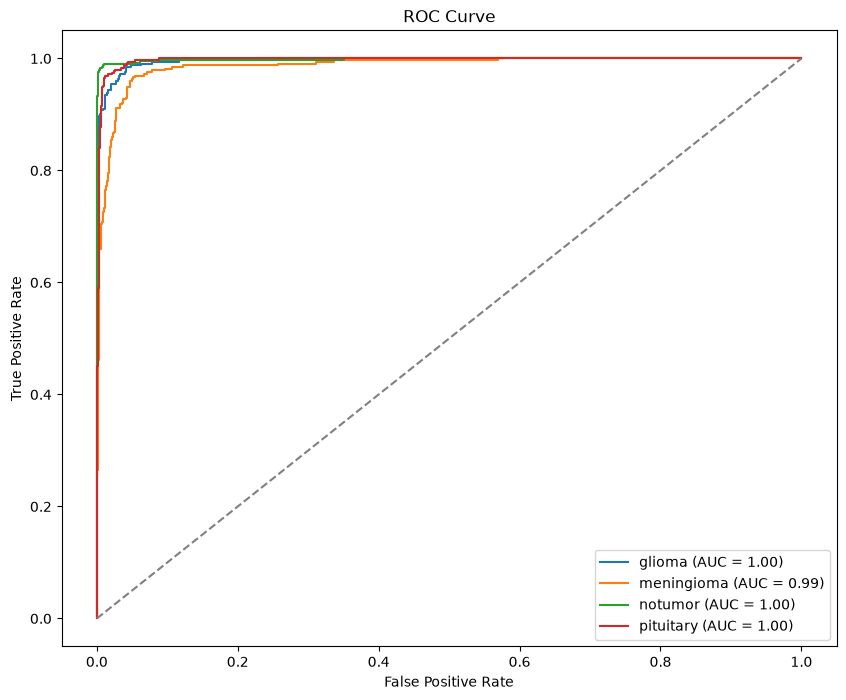

In [10]:
# 4. ROC Curve and AUC
# Binarize the test labels and predictions for multi-class ROC
test_labels_bin = label_binarize(test_labels_encoded, classes=np.arange(NUM_CLASSES))
test_predictions_bin = test_predictions  # The predicted probabilities for each class

# Compute ROC curve and ROC AUC for each class
fpr, tpr, roc_auc = {}, {}, {}
for i in range(NUM_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(test_labels_bin[:, i], test_predictions_bin[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curve
plt.figure(figsize=(10, 8))
for i in range(NUM_CLASSES):
    plt.plot(fpr[i], tpr[i], label=f'{CLASS_NAMES[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')  # Diagonal line
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()


### Save the model

In [11]:
os.makedirs(MODELS_DIR, exist_ok=True)
MODEL_PATH = os.path.join(MODELS_DIR, "brainscan_eda_vgg16.h5")
model.save(MODEL_PATH)
print(f"Modèle enregistré : {MODEL_PATH}")


Modèle enregistré : /home/moali/projects/brainscan/artifacts/models/brainscan_eda_vgg16.h5


In [12]:
from tensorflow.keras.models import load_model
model = load_model(MODEL_PATH)


### MRI Tumor Detection System

In [13]:
from keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Class labels, in the exact order used to encode the training labels
class_labels = list(CLASS_NAMES)


def detect_and_display(img_path, model, image_size=128):
    """
    Function to detect tumor and display results.
    If no tumor is detected, it displays "No Tumor".
    Otherwise, it shows the predicted tumor class and confidence.
    """
    try:
        # Load and preprocess the image (same raw 0-255 pixels as during training)
        img = load_img(img_path, target_size=(image_size, image_size))
        img_array = img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension

        # Make a prediction
        predictions = model.predict(img_array, verbose=0)
        predicted_class_index = np.argmax(predictions, axis=1)[0]
        confidence_score = np.max(predictions, axis=1)[0]

        # Determine the class
        if class_labels[predicted_class_index] == 'notumor':
            result = "No Tumor"
        else:
            result = f"Tumor: {class_labels[predicted_class_index]}"

        # Display the image with the prediction
        plt.imshow(load_img(img_path))
        plt.axis('off')
        plt.title(f"{result} (Confidence: {confidence_score * 100:.2f}%)")
        plt.show()

    except Exception as e:
        print("Error processing the image:", str(e))


### test

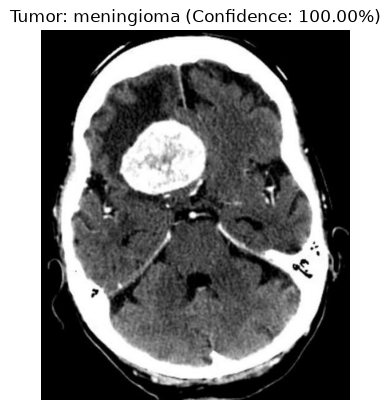

In [14]:
image_path = os.path.join(RAW_DATA_DIR, "meningioma", "Te-me_0015.jpg")
detect_and_display(image_path, model)
